# 05. Оптимизация портфеля (Марковиц)

На этапе 4 мы измеряли риск готового портфеля. Теперь обратная задача: **подобрать веса**.
Одна идея в основе всего ноутбука: оптимизатор безупречно решает задачу, которую ему дали, но задача составлена из оценок с ошибками, поэтому главный вопрос — насколько можно верить этим оценкам.

Геометрия и вывод формул — в [docs/lagrange_multipliers.md](../docs/lagrange_multipliers.md).

In [1]:
import sys; sys.path.append('..')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
pd.set_option('display.precision', 3)
from src.data import *
from src.risk import *
from src.optimize import *
from src.backtest import *
from src.plots import *

r = simple_returns(clean_prices(load_prices()))
S = covariance_matrix(r) * TRADING_DAYS   # годовая Σ
mu = expected_returns(r)                  # годовая μ

def stats(w):
    return {'доходность': w @ mu, 'риск': np.sqrt(w @ S @ w), 'Σ|w|': w.abs().sum(), 'макс. вес': w.max(), 'мин. вес': w.min()}

## 1. Портфель минимального риска
Прогноз доходности здесь не нужен: только $\min w^\top\Sigma w$ при $\mathbf 1^\top w = 1$. Условие Лагранжа даёт $w \propto \Sigma^{-1}\mathbf 1$.

**Проверка формулы.** В оптимуме $\Sigma w$ — одно и то же число для всех активов: ни один небольшой перенос веса с актива на актив уже не снижает риск.

In [2]:
w_mv = min_variance(S)
check = S @ w_mv
print(f'Σw: от {check.min():.6f} до {check.max():.6f}  (должны совпасть)')

w_mv_lo = min_variance_long_only(S)
ew = pd.Series(1 / len(S), index=S.index)
pd.DataFrame({'1/N': stats(ew), 'MinVar': stats(w_mv), 'MinVar, только покупки': stats(w_mv_lo)}).T

Σw: от 0.008329 до 0.008329  (должны совпасть)


,доходность,риск,Σ|w|,макс. вес,мин. вес
1/N,0.175,0.136,1.000,0.037,0.037
MinVar,0.102,0.091,1.351,0.295,-0.042
"MinVar, только покупки",0.097,0.092,1.000,0.292,0.000


In [3]:
print('MinVar, только покупки — ненулевые веса:')
print(w_mv_lo[w_mv_lo > 0.005].sort_values(ascending=False).round(3).to_string())

MinVar, только покупки — ненулевые веса:
TLT     0.292
GLD     0.151
KO      0.108
JNJ     0.107
CVX     0.048
XOM     0.046
MSFT    0.046
WMT     0.043
PG      0.034
JPM     0.031
UNH     0.025
WFC     0.022
MRK     0.018
ABBV    0.016
ORCL    0.011


**Вывод.** Риск падает с 13.6% у 1/N до 9.1–9.2%. Оптимизатор сам уходит в активы, слабо связанные с акциями: TLT и GLD дают 44% портфеля с запретом коротких продаж. Цена этого — меньшая доходность на этой истории: 9.7% против 17.5%.

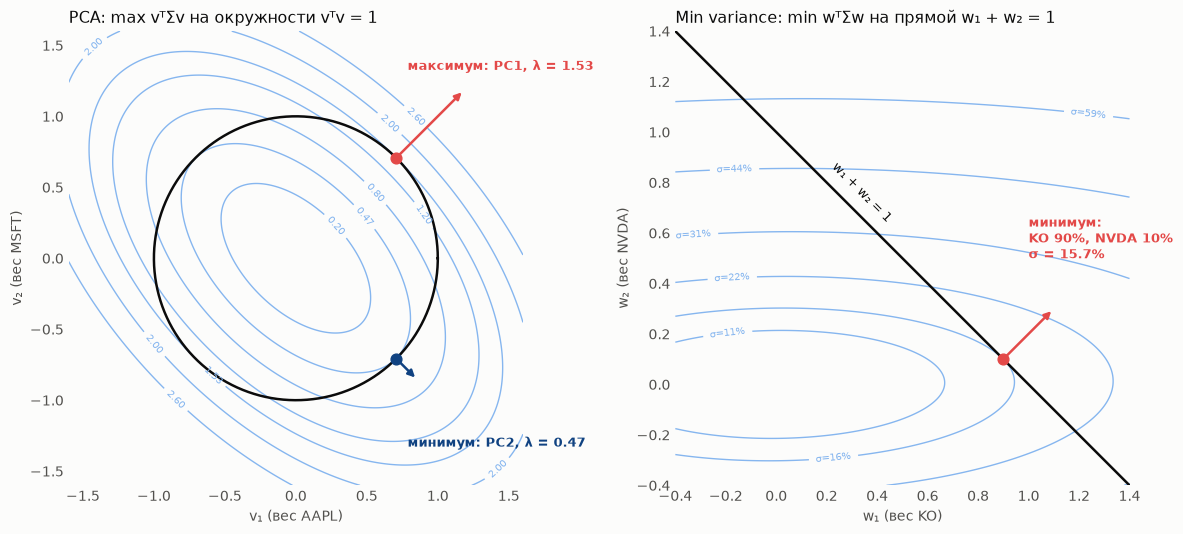

In [4]:
lagrange_geometry(r[['AAPL', 'MSFT']].corr(),
                  covariance_matrix(r[['KO', 'NVDA']]) * TRADING_DAYS,
                  save_as='05_lagrange_geometry.png');

## 2. Граница эффективности (на всей истории)
Добавляем доходность: для каждой целевой доходности ищем минимальный риск. Точка с лучшим Sharpe — $w \propto \Sigma^{-1}\mu$.

**Важно:** здесь оптимизатор видит те же данные, на которых его оценивают (*in-sample*), поэтому картинка показывает лучшее, что можно было выбрать задним числом, а не то, что можно было заработать.

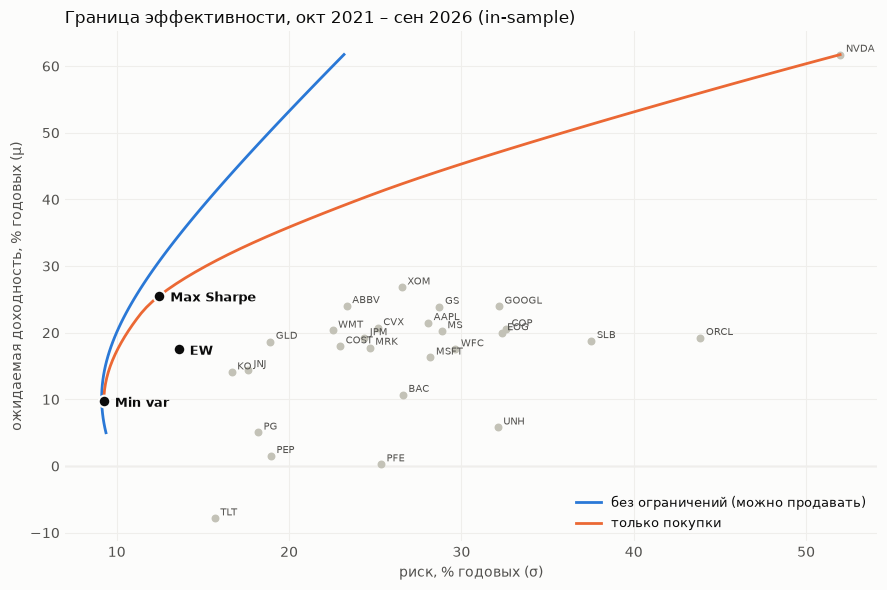

In [5]:
w_ms_lo = max_sharpe_long_only(mu, S)
assets = pd.DataFrame({'vol': np.sqrt(np.diag(S)), 'ret': mu})
ret_mv = w_mv_lo @ mu
curves = {
    'без ограничений (можно продавать)': frontier(mu, S, np.linspace(0.05, mu.max(), 80)),
    'только покупки': frontier_long_only(mu, S, np.linspace(ret_mv, mu.max() - 1e-4, 60)),
}
points = {'Min var': (np.sqrt(w_mv_lo @ S @ w_mv_lo), ret_mv),
          'Max Sharpe': (np.sqrt(w_ms_lo @ S @ w_ms_lo), w_ms_lo @ mu),
          'EW': (np.sqrt(ew @ S @ ew), ew @ mu)}
efficient_frontier(assets, curves, points, 'Граница эффективности, окт 2021 – сен 2026 (in-sample)',
                   save_as='05_efficient_frontier.png');

In [6]:
w_ms = max_sharpe(mu, S)
pd.DataFrame({'MaxSharpe': stats(w_ms), 'MaxSharpe, только покупки': stats(w_ms_lo)}).T.assign(
    Sharpe=lambda d: d['доходность'] / d['риск'])

,доходность,риск,Σ|w|,макс. вес,мин. вес,Sharpe
MaxSharpe,0.580,0.218,5.401,0.575,-0.424,2.664
"MaxSharpe, только покупки",0.255,0.125,1.000,0.246,0.000,2.048


**Вывод.** Задним числом MaxSharpe обещает Sharpe 2.66 и позиции на 5.4 доллара на каждый доллар капитала. Это лучший выбор для уже прошедшей истории, а не прогноз. Проверять его нужно на данных, которых он не видел.

## 3. Какой оценке можно верить
Обе оценки шумные, но в разной степени. Ошибка средней доходности за $T$ лет:

$$\text{SE}(\hat\mu) = \frac{\sigma}{\sqrt T}$$

Она зависит от риска актива и длины истории, а от самой доходности не зависит. За два года $\sqrt T \approx 1.41$.

In [7]:
W, STEP = 504, 21
recent = r.iloc[-W:]
vols = recent.std() * np.sqrt(TRADING_DAYS)
se = vols / np.sqrt(W / TRADING_DAYS)
print(f'Ошибка годовой μ на двух годах (медиана): {se.median():.1%}')
print(f'Типичная величина годовой μ (медиана |μ|): {(recent.mean() * TRADING_DAYS).abs().median():.1%}')
print(f'Самая шумная оценка: {se.idxmax()}, ±{se.max():.1%}; самая точная: {se.idxmin()}, ±{se.min():.1%}')

Ошибка годовой μ на двух годах (медиана): 19.2%
Типичная величина годовой μ (медиана |μ|): 19.2%
Самая шумная оценка: ORCL, ±40.4%; самая точная: TLT, ±8.2%


In [8]:
# Насколько оценка за два года похожа на оценку за следующие два года (корреляция по активам/парам)
iu = np.triu_indices(r.shape[1], 1)
rows = []
for s in range(W, len(r) - W + 1, STEP):
    past, next_ = r.iloc[s - W:s], r.iloc[s:s + W]
    cp, cn = past.cov().to_numpy(), next_.cov().to_numpy()
    rows.append({'средние доходности': np.corrcoef(past.mean(), next_.mean())[0, 1],
                 'дисперсии': np.corrcoef(np.diag(cp), np.diag(cn))[0, 1],
                 'ковариации': np.corrcoef(cp[iu], cn[iu])[0, 1]})
stability = pd.DataFrame(rows)
print(f'Сравнений: {len(stability)} (окна частично пересекаются)')
stability.mean().round(2).to_frame('связь прошлого с будущим')

Сравнений: 12 (окна частично пересекаются)


,связь прошлого с будущим
средние доходности,0.24
дисперсии,0.65
ковариации,0.83


**Вывод.** Типичная ошибка средней доходности за два года (19.2%) равна типичной величине самой доходности (19.2%): шум размером с сигнал. Шумные активы страдают сильнее: у ORCL ошибка ±40%, у TLT ±8%. Ковариации намного устойчивее: связь с будущим 0.83 против 0.24 у средних.

## 4. Walk-forward: честная проверка
Каждый месяц (21 день) считаем веса только по прошлым 504 дням и держим их следующий месяц. Издержки не учитываем — см. допущения в конце.

In [9]:
def ann(c): return c * TRADING_DAYS

strategies = {
    '1/N':                       lambda t: pd.Series(1 / t.shape[1], index=t.columns),
    'MinVar':                    lambda t: min_variance(ann(t.cov())),
    'MinVar + LW':               lambda t: min_variance(ann(ledoit_wolf(t)[0])),
    'MinVar + PCA(4)':           lambda t: min_variance(ann(pca_filtered_cov(t, 4))),
    'MinVar, только покупки':    lambda t: min_variance_long_only(ann(t.cov())),
    'MinVar + LW, только покупки':  lambda t: min_variance_long_only(ann(ledoit_wolf(t)[0])),
    'MinVar + PCA(4), только покупки': lambda t: min_variance_long_only(ann(pca_filtered_cov(t, 4))),
    'MaxSharpe':                 lambda t: max_sharpe(expected_returns(t), ann(t.cov())),
    'MaxSharpe, только покупки': lambda t: max_sharpe_long_only(expected_returns(t), ann(t.cov())),
    'MaxSharpe, риск 10%':       lambda t: max_sharpe_fixed_risk(expected_returns(t), ann(t.cov()), 0.10),
}
results = {name: walk_forward(r, f) for name, f in strategies.items()}
table = pd.DataFrame({k: summarize(v) for k, v in results.items()}).T
table.insert(0, 'итог $1', [(1 + v['returns']).prod() for v in results.values()])
ret = {k: v['returns'] for k, v in results.items()}
print('Тест:', ret['1/N'].index[0].date(), '–', ret['1/N'].index[-1].date(), '| пересчётов:', len(results['1/N']['log']))
table

Тест: 2023-10-05 – 2026-09-30 | пересчётов: 36


,итог $1,доходность,риск,Sharpe,обещанный риск,риск факт/обещ.,макс. просадка,оборот в год,плечо (Σ|w|)
1/N,1.831,0.211,0.117,1.795,0.130,0.899,-0.155,0.000,1.000
MinVar,1.591,0.160,0.088,1.817,0.083,1.055,-0.067,1.208,1.409
MinVar + LW,1.589,0.160,0.088,1.808,0.084,1.052,-0.070,0.976,1.316
MinVar + PCA(4),1.656,0.174,0.092,1.892,0.087,1.052,-0.067,1.229,1.480
"MinVar, только покупки",1.641,0.171,0.088,1.945,0.086,1.024,-0.071,0.752,1.000
"MinVar + LW, только покупки",1.643,0.171,0.089,1.933,0.086,1.029,-0.073,0.682,1.000
"MinVar + PCA(4), только покупки",1.727,0.188,0.089,2.119,0.088,1.012,-0.069,0.739,1.000
MaxSharpe,1.066,0.215,0.603,0.356,0.348,1.735,-0.775,21.879,8.591
"MaxSharpe, только покупки",2.117,0.262,0.140,1.875,0.127,1.103,-0.154,1.852,1.000
"MaxSharpe, риск 10%",1.513,0.149,0.135,1.101,0.100,1.350,-0.131,4.732,2.458


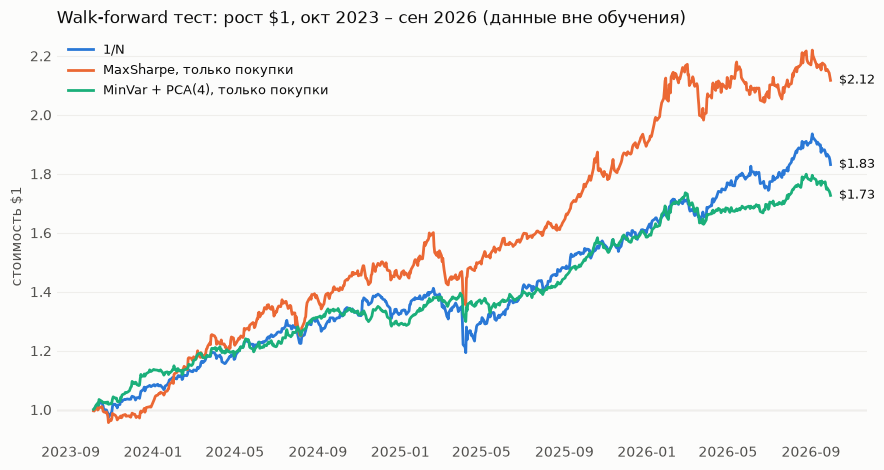

In [10]:
wealth_curves({'1/N': ret['1/N'],
               'MaxSharpe, только покупки': ret['MaxSharpe, только покупки'],
               'MinVar + PCA(4), только покупки': ret['MinVar + PCA(4), только покупки']},
              'Walk-forward тест: рост $1, окт 2023 – сен 2026 (данные вне обучения)',
              save_as='05_walk_forward_wealth.png');

**Вывод.**

- Обещанный риск у MinVar сбывается: факт/прогноз 1.01–1.06. У MaxSharpe без ограничений прогноз сильно занижен: 35% против 60%.
- Запрет коротких продаж работает как защита от ошибок оценки: MaxSharpe с ним даёт Sharpe 1.88, без него 0.36.
- Ledoit–Wolf почти ничего не меняет. Его δ в среднем около 0.05: при 504 днях на 27 активов сжимать почти нечего.
- Лидер по Sharpe — MinVar + PCA(4) с запретом коротких продаж (2.12). Отличим ли он от шума, проверяем ниже.

## 5. Отличимо ли это от шума
Три года — мало. Блочный бутстрэп пересобирает историю из случайных кусков по 21 дню и показывает, в каких пределах гуляет разность метрик двух стратегий.

In [11]:
def vol(x): return np.std(x, ddof=1) * np.sqrt(TRADING_DAYS)

pairs = [('Sharpe', sharpe, 'MaxSharpe, только покупки', '1/N'),
         ('Sharpe', sharpe, 'MinVar, только покупки', '1/N'),
         ('Sharpe', sharpe, 'MinVar + PCA(4), только покупки', '1/N'),
         ('Sharpe', sharpe, 'MinVar + PCA(4), только покупки', 'MinVar, только покупки'),
         ('риск', vol, 'MinVar, только покупки', '1/N'),
         ('риск', vol, 'MinVar + PCA(4), только покупки', '1/N')]
pd.DataFrame([{'метрика': m, 'A': a, 'B': b, **bootstrap_diff(ret[a], ret[b], stat=f)} for m, f, a, b in pairs]).round(3)

,метрика,A,B,разность,95% от,95% до,P(разность > 0)
0,Sharpe,"MaxSharpe, только покупки",1/N,0.079,-1.054,1.033,0.530
1,Sharpe,"MinVar, только покупки",1/N,0.150,-0.901,0.951,0.586
2,Sharpe,"MinVar + PCA(4), только покупки",1/N,0.324,-0.835,1.194,0.693
3,Sharpe,"MinVar + PCA(4), только покупки","MinVar, только покупки",0.174,-0.056,0.343,0.915
4,риск,"MinVar, только покупки",1/N,-0.030,-0.050,-0.013,0.000
5,риск,"MinVar + PCA(4), только покупки",1/N,-0.029,-0.052,-0.010,0.000


In [12]:
# NVDA попала в список активов, когда её рост уже был известен. Что будет без неё?
r_no = r.drop(columns='NVDA')
rows = {}
for name in ['1/N', 'MaxSharpe, только покупки', 'MinVar + PCA(4), только покупки']:
    s = summarize(walk_forward(r_no, strategies[name]))
    rows[name] = {'Sharpe с NVDA': table.loc[name, 'Sharpe'], 'Sharpe без NVDA': s['Sharpe'],
                  'доходность без NVDA': s['доходность'], 'риск без NVDA': s['риск']}
pd.DataFrame(rows).T

,Sharpe с NVDA,Sharpe без NVDA,доходность без NVDA,риск без NVDA
1/N,1.795,1.671,0.193,0.116
"MaxSharpe, только покупки",1.875,1.595,0.213,0.133
"MinVar + PCA(4), только покупки",2.119,2.039,0.182,0.089


**Вывод.** Надёжно отличимо от шума только снижение риска: у MinVar риск ниже, чем у 1/N, примерно на 3 процентных пункта, и весь 95% интервал лежит ниже нуля. Ни одно преимущество по Sharpe не доказано: интервалы накрывают ноль. Победа MaxSharpe с запретом коротких продаж зависит от NVDA: без неё он уступает 1/N (1.60 против 1.67). MinVar + PCA(4) от неё почти не зависит (2.04), но вариант выбран из нескольких на тех же данных, и это завышает его результат.

## 6. Почему провалился MaxSharpe без ограничений
У провала две причины. Их можно разделить, подменяя по одной входной оценке.

### 6.1. Какая оценка виновата: подмена
Подставляем настоящие данные следующих двух лет — намеренно заглядываем в будущее, это диагностика, а не стратегия. Масштаб во всех строках один: прогнозный риск 10%. Будущее окно включает месяц теста, поэтому результаты с будущими данными завышены: важен масштаб разницы.

In [13]:
def swap_test(mu_src, cov_src):
    out = []
    for s in range(W, len(r) - W + 1, STEP):
        past, future = r.iloc[s - W:s], r.iloc[s:s + W]
        m = {'прошлая': expected_returns(past), 'будущая': expected_returns(future),
             'одинаковая (MinVar)': pd.Series(1.0, index=r.columns)}[mu_src]
        c = {'прошлая': past.cov(), 'будущая': future.cov(), 'LW': ledoit_wolf(past)[0],
             'PCA(4)': pca_filtered_cov(past, 4)}[cov_src]
        out.append(r.iloc[s:s + STEP] @ max_sharpe_fixed_risk(m, ann(c), 0.10))
    x = pd.concat(out)
    return {'μ': mu_src, 'Σ': cov_src, 'доходность': x.mean() * TRADING_DAYS,
            'риск': x.std() * np.sqrt(TRADING_DAYS), 'Sharpe': sharpe(x), 'пересчётов': len(out)}

pd.DataFrame([swap_test(m, c) for m, c in [
    ('прошлая', 'прошлая'), ('прошлая', 'будущая'), ('будущая', 'прошлая'),
    ('одинаковая (MinVar)', 'прошлая'), ('прошлая', 'LW'), ('прошлая', 'PCA(4)')]]).round(3)

,μ,Σ,доходность,риск,Sharpe,пересчётов
0,прошлая,прошлая,0.131,0.131,0.996,12
1,прошлая,будущая,0.030,0.118,0.253,12
2,будущая,прошлая,0.601,0.116,5.177,12
3,одинаковая (MinVar),прошлая,0.284,0.092,3.099,12
4,прошлая,LW,0.126,0.128,0.987,12
5,прошлая,PCA(4),0.053,0.146,0.361,12


**Вывод.** Идеальная ковариация не помогает (Sharpe 0.25), идеальная доходность даёт скачок (5.18). С той же прошлой ковариацией, но без прогноза доходности Sharpe равен 3.10. Улучшенные оценки ковариации MaxSharpe не спасают (0.99 и 0.36). Главный виновник — оценка доходности. Пересчётов всего 12, поэтому числа приблизительные.

### 6.2. Что раздувает позиции: деление на сумму
Формула считает $x = \Sigma^{-1}\mu$, а затем $w = x / \mathbf 1^\top x$, чтобы веса давали 1. Если покупки и продажи в $x$ почти гасят друг друга, знаменатель мал, и все позиции умножаются на большое число.

In [14]:
rows = []
for s in range(W, len(r), STEP):
    t = r.iloc[s - W:s]
    x = pd.Series(np.linalg.solve(ann(t.cov()).to_numpy(), expected_returns(t).to_numpy()), index=r.columns)
    w = x / x.sum()
    rows.append({'дата': r.index[s].date(), 'сумма x': x.sum(), 'Σ|w|': w.abs().sum(),
                 'покупка': w.idxmax(), 'вес': w.max(), 'продажа': w.idxmin(), 'вес ': w.min(),
                 'итог месяца': (1 + r.iloc[s:s + STEP] @ w).prod() - 1})
d = pd.DataFrame(rows)
print(f"Σ|w|: медиана {d['Σ|w|'].median():.1f}, среднее {d['Σ|w|'].mean():.1f}, максимум {d['Σ|w|'].max():.1f}")
print(f"Сумма x: медиана {d['сумма x'].median():.1f}, минимум {d['сумма x'].min():.2f}")
print(f"Связь Σ|w| и 1/сумма x: {np.corrcoef(d['Σ|w|'], 1 / d['сумма x'].abs())[0, 1]:.2f}")
d.sort_values('Σ|w|', ascending=False).head(5).round(2)

Σ|w|: медиана 4.9, среднее 8.6, максимум 35.4
Сумма x: медиана 19.6, минимум 1.78
Связь Σ|w| и 1/сумма x: 0.96


,дата,сумма x,Σ|w|,покупка,вес,продажа,вес,итог месяца
1,2023-11-03,1.78,35.37,XOM,2.76,BAC,-5.36,-0.61
0,2023-10-05,2.14,29.89,XOM,2.43,BAC,-5.24,-0.38
5,2024-03-07,5.05,22.69,MRK,2.83,BAC,-1.96,0.16
4,2024-02-06,4.84,21.81,MRK,2.63,PFE,-2.10,0.45
6,2024-04-08,5.81,19.85,MRK,2.31,BAC,-1.83,-0.31


In [15]:
# То же направление Σ⁻¹μ, те же месяцы, разный масштаб
table.loc[['MaxSharpe', 'MaxSharpe, риск 10%'],
          ['итог $1', 'доходность', 'риск', 'Sharpe', 'обещанный риск', 'макс. просадка', 'плечо (Σ|w|)', 'оборот в год']]

,итог $1,доходность,риск,Sharpe,обещанный риск,макс. просадка,плечо (Σ|w|),оборот в год
MaxSharpe,1.066,0.215,0.603,0.356,0.348,-0.775,8.591,21.879
"MaxSharpe, риск 10%",1.513,0.149,0.135,1.101,0.100,-0.131,2.458,4.732


**Вывод.** Среднее 8.6 создают отдельные экстремальные месяцы: медиана 4.9, максимум 35. Размер позиций почти полностью следует за делением на сумму (связь 0.96). В ноябре 2023 сумма упала до 1.78, и портфель потерял 61% за месяц.

Фиксированный риск убирает катастрофу (просадка −13% вместо −78%, Sharpe 1.10 вместо 0.36), но не догоняет 1/N (1.80): ошибочный прогноз доходности остаётся. Факт риска здесь тоже выше обещанного: 13.5% против 10%. Две причины подтвердились по отдельности: **прогноз выбирает неверные ставки, а деление на маленькую сумму их раздувает.**

## 7. Устойчивость: длина истории
Окно 504 дня было выбрано заранее. Проверим другие длины на **тех же месяцах теста**: меняется только история, по которой считаются веса. MaxSharpe берём с фиксированным риском, чтобы деление на сумму не мешало сравнению.

In [16]:
TEST_START = W
rows, se_rows = [], []
for window in (504, 252, 126):
    sub = r.iloc[TEST_START - window:]
    for name in ['MinVar', 'MinVar, только покупки', 'MaxSharpe, риск 10%', 'MaxSharpe, только покупки', 'MaxSharpe']:
        res = walk_forward(sub, strategies[name], window=window)
        assert res['returns'].index[0] == r.index[TEST_START]   # тест начинается в один и тот же день
        s = summarize(res)
        rows.append({'стратегия': name, 'дней истории': window, 'Sharpe': s['Sharpe'], 'риск': s['риск'],
                     'обещанный риск': s['обещанный риск'], 'факт/обещ.': s['риск факт/обещ.'], 'оборот в год': s['оборот в год']})
    se_rows.append({'дней истории': window, 'ошибка годовой μ (медиана)': np.median(
        [(r.iloc[s - window:s].std() * np.sqrt(TRADING_DAYS) / np.sqrt(window / TRADING_DAYS)).median()
         for s in range(TEST_START, len(r), STEP)])})
display(pd.DataFrame(se_rows).set_index('дней истории').round(3))
pd.DataFrame(rows).set_index(['стратегия', 'дней истории']).round(3)

,ошибка годовой μ (медиана)
дней истории,
504,0.176
252,0.242
126,0.320


,,Sharpe,риск,обещанный риск,факт/обещ.,оборот в год
стратегия,дней истории,,,,,
MinVar,504,1.817,0.088,0.083,1.055,1.208
"MinVar, только покупки",504,1.945,0.088,0.086,1.024,0.752
"MaxSharpe, риск 10%",504,1.101,0.135,0.100,1.350,4.732
"MaxSharpe, только покупки",504,1.875,0.140,0.127,1.103,1.852
MaxSharpe,504,0.356,0.603,0.348,1.735,21.879
MinVar,252,1.718,0.086,0.072,1.195,2.319
"MinVar, только покупки",252,1.815,0.086,0.076,1.131,1.311
"MaxSharpe, риск 10%",252,0.911,0.141,0.100,1.406,7.901
"MaxSharpe, только покупки",252,1.951,0.139,0.115,1.204,3.040


**Вывод.** MaxSharpe с фиксированным риском теряет больше всех: Sharpe 1.10 при двух годах, 0.91 при годе и 0.19 при шести месяцах. Ошибка оценки доходности за это время почти удваивается: с 17.6% до 32.0%. MinVar почти не меняется по Sharpe (1.82, 1.72, 1.76), но его прогноз риска становится всё более оптимистичным: факт превышает его на 6% при двух годах и на 36% при шести месяцах, а оборот растёт с 1.2 до 4.3 в год.

Для средней доходности важна длина истории в годах, а для ковариации — число наблюдений. Поэтому короткая история сильнее бьёт по прогнозу доходности.

MaxSharpe с делением на сумму падает неровно: 0.36, 0.69 и 0.12. Всё решают несколько месяцев с огромными позициями, поэтому год, оказавшийся лучше двух лет, — скорее случайность.

## Итог этапа

1. **Риск оценивается намного лучше доходности.** Поэтому MinVar держит обещания, а MaxSharpe без ограничений — нет.
2. **Самая сложная модель проиграла самой простой.** MaxSharpe без ограничений выглядел лучше всех задним числом (Sharpe 2.66) и оказался худшим на тесте (0.36). Простой 1/N дал 1.80.
3. **Ограничения полезны не меньше формул.** Запрет коротких продаж в этих данных помог заметно сильнее, чем уточнение ковариации через Ledoit–Wolf.

## Допущения и ограничения

- **Отбор активов задним числом.** Список составлен в 2026 году из компаний, известных сегодня, поэтому все результаты завышены. Особенно это касается NVDA.
- **Удачный период.** Sharpe 1.8 у 1/N — результат роста рынка за эти три года, а не норма. Выводы относятся к сравнению стратегий, а не к ожидаемому заработку.
- **Издержек нет.** При 10 б.п. за сделку MaxSharpe без ограничений потерял бы около 4.4% годовых только на ежемесячных пересчётах, MinVar с запретом коротких продаж — около 0.15%.
- **Оборот занижен.** Считаются только ежемесячные пересчёты. Удержание фиксированных весов внутри месяца требует ежедневной подстройки, которая здесь не учтена, поэтому оборот 1/N показан как 0.
- **Короткие позиции и заём бесплатны.** На практике за них платят, и это особенно бьёт по стратегиям с большим плечом.
- **Множественные сравнения.** На одном периоде сравнивались 10 стратегий, поэтому лучший результат отчасти объясняется удачей.
- **Выбор окна.** Окно 504 дня и шаг 21 день заданы заранее. Длина окна проверена в разделе 7 на тех же месяцах, шаг на устойчивость не проверялся.